# Project 2 – Logistic regression: latent space analysis
**Question:** what does the data look like from the point of view of the logistic regression, and where do persons with prediabetes/diabetes end up?

Logistic regression has no hidden layers: logit = b + Σ wⱼxⱼ. The closest thing to a "latent space" is therefore:
- **Input x** (21 standardized features), and
- **Weighted inputs w·x** (each feature multiplied by its weight = its contribution to the logit).

We project both to 2-D with t-SNE, UMAP and PCA.

## 1. Load the trained model
We run `Project2_LogReg_clean.ipynb` with `%run` to get the trained `model` and the same data split. No new model is trained.
The cell takes a few minutes; its output is hidden (`main_log.show()` shows it).

In [1]:
%%capture main_log
%run Project2_LogReg_clean.ipynb

In [2]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

plt.close('all')
warnings.filterwarnings('ignore', message='n_jobs value')
warnings.filterwarnings('ignore', message='compatibility_layout', category=FutureWarning)
SEED = 42

test_proba = model.predict_proba(X_test)[:, 1]
print(f'Test balanced accuracy of the loaded model: {balanced_accuracy_score(y_test, (test_proba >= 0.5).astype(int)):.3f}')

Test balanced accuracy of the loaded model: 0.743


## 2. Representations

In [3]:
# Random sample of 5000 test persons (t-SNE/UMAP are slow on all ~50,000)
N_LATENT = 5000
lat_idx = np.random.default_rng(SEED).choice(len(X_test), size=N_LATENT, replace=False)
lat_y012 = y012_test[lat_idx]
print('Classes in the sample (0, 1, 2):', np.bincount(lat_y012))

X_lat = X_test[lat_idx]
W_lat = X_lat * model.coef_[0]          # each feature's contribution to the logit
logit_lat = model.decision_function(X_lat)
assert np.allclose(W_lat.sum(axis=1) + model.intercept_[0], logit_lat)   # contributions + intercept = logit

reps = {
    'Input x (21)': X_lat,
    'Weighted inputs w·x (21)': W_lat,
}

Classes in the sample (0, 1, 2): [4232   92  676]


In [4]:
pca_embs, pca_vars, tsne_embs, umap_embs = {}, {}, {}, {}
for name, R in reps.items():
    pca = PCA(n_components=2, random_state=SEED)
    pca_embs[name] = pca.fit_transform(R)
    pca_vars[name] = pca.explained_variance_ratio_
    tsne_embs[name] = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(R)
    umap_embs[name] = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(R)
    print(f'{name:28s} done')

class_colors = {0: 'lightgray', 1: '#0070e0', 2: '#e06c00'}
class_labels = {0: 'No diabetes (0)', 1: 'Prediabetes (1)', 2: 'Diabetes (2)'}


def scatter_by_label(ax, emb, title, xlabel, ylabel, legend=False):
    for c in [0, 2, 1]:   # big class first, so the small classes stay visible on top
        m = lat_y012 == c
        ax.scatter(emb[m, 0], emb[m, 1], s=4, alpha=0.6, color=class_colors[c], label=f'{class_labels[c]}  n={m.sum()}')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(labelsize=8)
    if legend:
        ax.legend(markerscale=3, fontsize=7)

Input x (21)                 done


Weighted inputs w·x (21)     done


## 3. t-SNE and UMAP

*Reading the axes:* t-SNE 1/2 and UMAP 1/2 have **no unit and no meaning** on their own: they are not features, and the numbers change with the random seed. Only *which points lie close to each other* can be interpreted, not the position on an axis or the distance between far-apart groups. PCA axes (Section 4) do have a meaning: a fixed linear combination of the features.

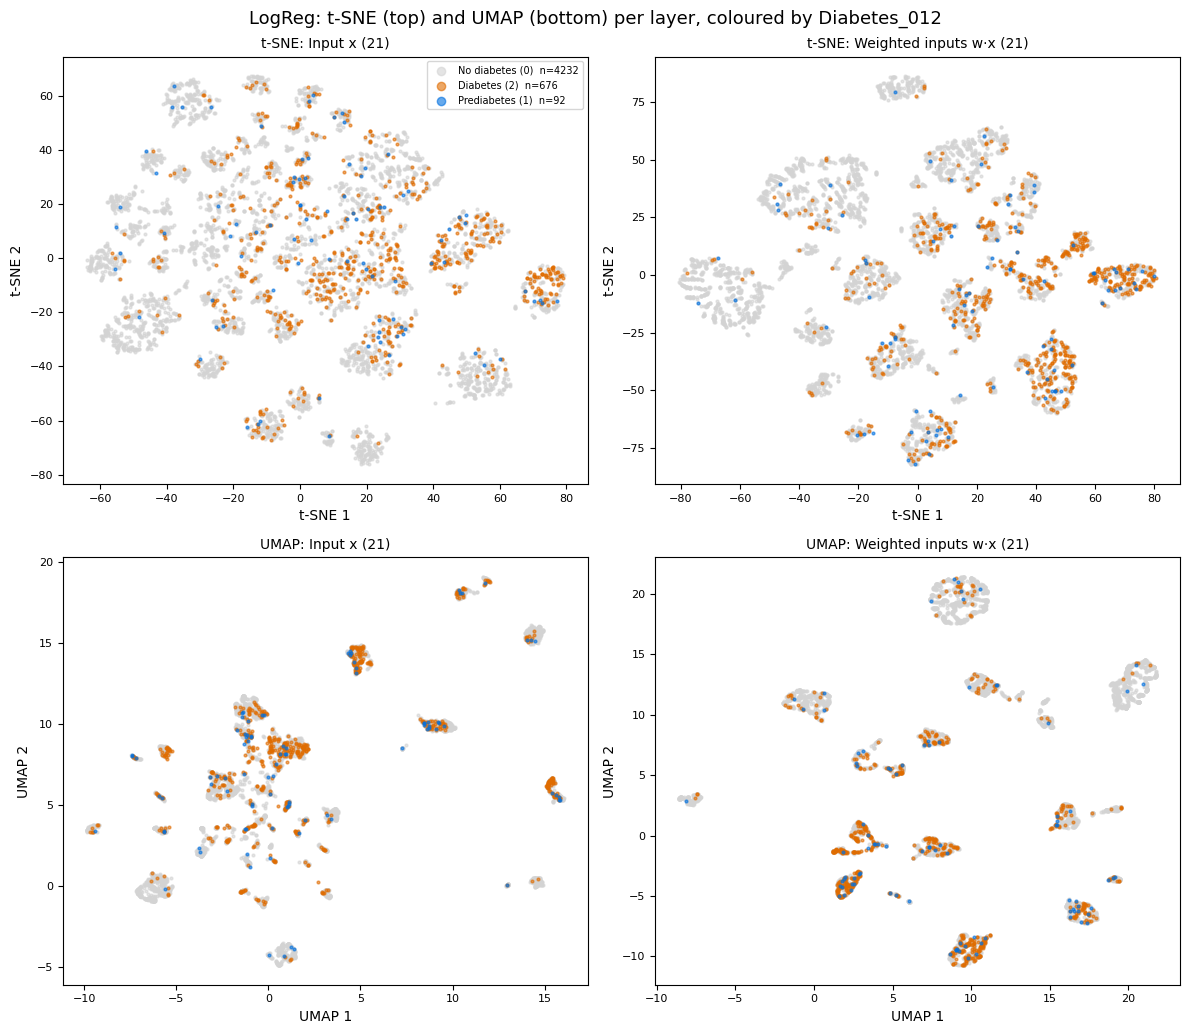

In [5]:
fig, axes = plt.subplots(2, len(reps), figsize=(6 * len(reps), 10.5))
for i, name in enumerate(reps):
    scatter_by_label(axes[0, i], tsne_embs[name], f't-SNE: {name}', 't-SNE 1', 't-SNE 2', legend=(i == 0))
    scatter_by_label(axes[1, i], umap_embs[name], f'UMAP: {name}', 'UMAP 1', 'UMAP 2')
fig.suptitle(f'{MODEL_TAG}: t-SNE (top) and UMAP (bottom) per layer, coloured by Diabetes_012', fontsize=13)
plt.tight_layout()
plt.show()

**Analysis**
- **Input x:** many small islands, one per common combination of binary answers. Diabetes cases are spread over almost all islands, so the raw input has no clear class structure.
- **Weighted inputs w·x:** the islands are still there, but fewer and larger. Features with a small weight are shrunk towards 0, so islands that only differ on unimportant features merge. Now some islands are almost only healthy persons, while others contain most of the diabetes cases.
- Unlike the NN, the island structure is **never removed**: logistic regression can only stretch or shrink each input axis, not bend the space. Different groups of persons get a high risk for different reasons (different combinations of risk factors), and they stay in separate islands.
- **Prediabetes** (blue) does not form its own group; it lies inside the same islands as diabetes.

## 4. PCA

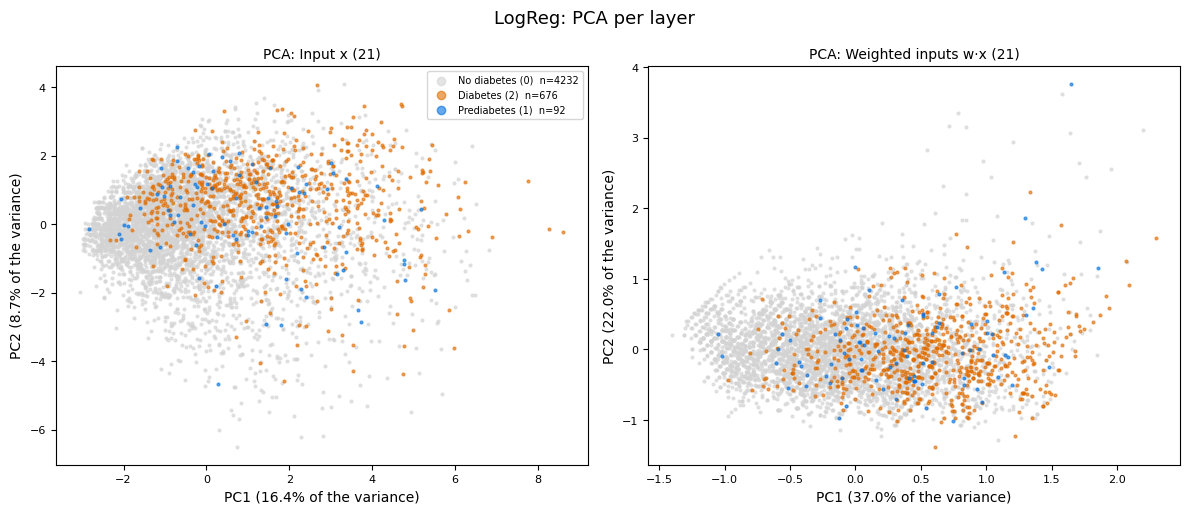

Correlation between PC1 of w·x and the logit: +0.895
Correlation between PC2 of w·x and the logit: -0.132


In [6]:
fig, axes = plt.subplots(1, len(reps), figsize=(6 * len(reps), 5.2))
for i, name in enumerate(reps):
    v = pca_vars[name]
    scatter_by_label(axes[i], pca_embs[name], f'PCA: {name}',
                     f'PC1 ({100*v[0]:.1f}% of the variance)', f'PC2 ({100*v[1]:.1f}% of the variance)', legend=(i == 0))
fig.suptitle(f'{MODEL_TAG}: PCA per layer', fontsize=13)
plt.tight_layout()
plt.show()

for k in range(2):
    r = np.corrcoef(pca_embs['Weighted inputs w·x (21)'][:, k], logit_lat)[0, 1]
    print(f'Correlation between PC{k + 1} of w·x and the logit: {r:+.3f}')

**Analysis**
- The share of variance on PC1 rises from **16% (input) to 37% (w·x)**. Weighting by the model concentrates the variation on the features that matter for the prediction.
- PC1 of the weighted inputs correlates strongly with the logit (**r ≈ 0.90**), so moving from left to right in the PCA plot is almost the same as moving from low to high predicted risk. Healthy persons lie to the left, diabetes cases to the right, with a large overlap in the middle.
- For logistic regression, a simple linear projection is therefore enough to see what the model does; t-SNE/UMAP mainly show the island structure of the data itself.

## 5. Conclusion
- The logistic regression does not build a new representation: its "latent space" is the input with each axis rescaled by its weight.
- The weighting moves the important variation onto one direction (PC1 of w·x ≈ the logit, r ≈ 0.90), which separates healthy from diabetes, but with a large overlap.
- The island structure of the binary features remains, so persons at risk are split into several groups rather than lying on one continuous axis.
- Compared with the NN (`Project2_NN_latent_analysis.ipynb`), whose last hidden layer is one continuous risk band (PC1 = 81%), logistic regression keeps much more of the original structure of the data.